In [1]:
# Google Colab setup: install the packages this notebook uses.
# Runs only on Colab; skipped in Binder or a local Jupyter install.
import sys
if "google.colab" in sys.modules:
    %pip install -q numpy pandas scipy matplotlib

# Lecture 25, Floods II: flood frequency analysis, design floods and climate change

> From 25 dots on a probability plot to the 100-year flood, and how sure we can be of it

Lecture 24 ended with the Chattooga's 25 annual maxima on a probability plot. The points stop at $T = 26$ years, but a bridge or a dam needs the 50-year, 100-year or even rarer flood. **Flood frequency analysis** fits a probability distribution through the points and reads the rare floods off the fitted curve. This lecture uses the **frequency factor method** of Chow, Maidment & Mays (1988), Chapter 12, with two distributions: **Gumbel** (extreme value type I) and **log-Pearson type III**, the distribution of the US Bulletin 17 guidelines. It then asks how uncertain the answer is, which flood to design for, and what a warmer climate does to the 100-year flood.

By the end of this lecture you should be able to:

- write the frequency factor equation $x_T = \bar x + K_T s$ and say what each part means,
- fit a Gumbel distribution by the method of moments, by hand and in code,
- fit a log-Pearson III distribution with $K_T$ from the skew of the logarithms,
- read the 10-, 50- and 100-year floods from both fits and judge how uncertain they are,
- explain how design floods are chosen and how climate change shifts the $T$-year flood.

The workbook `data/extremes/lec25/lec25_worked_examples.xlsx` repeats the hand example and both Chattooga fits (sheets `Gumbel` and `LP3`) with live formulas.

## Words you need

| Word | Plain meaning | Tiny example |
|---|---|---|
| distribution (fitted) | a smooth curve that gives the chance of every flood size; "fitting" means choosing its few numbers (parameters) to match the data | Gumbel with $u = 92$, $\alpha = 77$ m$^3$/s |
| method of moments | fitting by making the curve's mean and standard deviation equal to those of the data (Lecture 17) | mean 440, $s$ = 142 |
| standard deviation $s$ | the typical distance of the values from their mean | for 2, 4, 6 it is 2 |
| skew $C_s$ | which side has the long tail; positive means a few very large values | flood series are usually positively skewed |
| logarithm, $\log_{10}$ | the power of 10: $\log_{10} 100 = 2$, $\log_{10} 1000 = 3$; it pulls in the long tail | used in log-Pearson III |
| frequency factor $K_T$ | how many standard deviations the $T$-year flood lies above the mean | $K_{100} = 3.14$ for Gumbel |
| extrapolation | reading a curve beyond the range of the data | the 100-year flood from 25 years |
| bootstrap | re-drawing the record many times at random (with repeats) to see how much an estimate could change | 2000 re-drawn 25-year records |
| design flood | the flood a structure is built to pass safely | the 100-year flood for a small dam |
| PMF | probable maximum flood: the largest flood thought physically possible at a site, from the probable maximum precipitation (PMP), not from a return period | used for large dams |
| stationary | the odds of floods do not change over the years | assumed by $T = 1/p$ |

## Notation

Same symbols as Lecture 24, plus those of the fits (Chow et al., 1988, Chapter 12).

| Symbol | Meaning | Units | Code / spreadsheet |
|:--|:--|:--|:--|
| $x$, $n$ | annual maximum, number of years | m$^3$/s, years | `x`, `n` |
| $T$, $p = 1/T$ | return period, exceedance probability | years, - | `T`, `p` |
| $\bar x$, $s$ | sample mean and standard deviation of $x$ (divisor $n-1$) | m$^3$/s | `x_bar`, `s` |
| $K_T$ | frequency factor for return period $T$ | - | `K_T` |
| $x_T$ | $T$-year flood, $x_T = \bar x + K_T s$ | m$^3$/s | `x_T` |
| $u$, $\alpha$ | Gumbel location and scale ($u$ is the $x_0$ of Lecture 17) | m$^3$/s | `u`, `alpha` |
| $y_T$ | Gumbel reduced variate, $-\ln[\ln(T/(T-1))]$, the plot axis | - | `y_T` |
| $y = \log_{10} x$ | logarithm of a flow (no subscript) | - | `y` |
| $\bar y$, $s_y$, $C_s$ | mean, standard deviation and skew coefficient of $y$ | - | `y_bar`, `s_y`, `Cs` |
| $z$ | standard normal value with exceedance probability $p$ | - | `z` |
| $N$, $R$ | design life, risk $R = 1 - (1 - 1/T)^N$ (Lecture 24) | years, - | `N`, `R` |
| $\Delta T_{air}$, $c$ | warming, and the factor $c = 1.07^{\Delta T_{air}}$ applied to floods (Section 8) | K, - | `dT`, `c` |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

URL = "https://raw.githubusercontent.com/drvivekhydro/hydroclimatology/main/data/chattooga_daily.csv"
try:
    df = pd.read_csv("data/chattooga_daily.csv", comment="#", parse_dates=["date"], index_col="date")
except FileNotFoundError:                      # e.g. on Colab without the repository
    df = pd.read_csv(URL, comment="#", parse_dates=["date"], index_col="date")

Q = df["q_mm"] * 536 / 86.4                    # daily mean discharge, m3/s
ams = Q.groupby(df.index.year).max()           # annual maximum series of Lecture 24
x, n = ams.to_numpy(), len(ams)
m = np.arange(1, n + 1)
x_sorted = np.sort(x)[::-1]                    # largest first, rank m = 1
T_emp = (n + 1) / m                            # Weibull plotting position, Lecture 24
y_T = lambda T: -np.log(np.log(T / (T - 1)))   # Gumbel reduced variate (plot axis)
print(f"n = {n};  x_bar = {x.mean():.2f} m3/s;  s = {x.std(ddof=1):.2f} m3/s;  largest {x.max():.1f} (T = {T_emp[0]:.0f} yr)")

n = 25;  x_bar = 136.43 m3/s;  s = 99.36 m3/s;  largest 523.7 (T = 26 yr)


## 1) The frequency factor method

Chow's idea is to write every $T$-year flood as "the mean plus some number of standard deviations":

$$
x_T = \bar x + K_T\, s .
$$

The data give $\bar x$ and $s$. The **frequency factor** $K_T$ depends only on the chosen distribution and on $T$ (and, for some distributions, on the skew). For example, if $K_{100} = 3$, the 100-year flood lies 3 standard deviations above the mean. Choosing a distribution therefore means choosing a formula or table for $K_T$. Fitting by the **method of moments** (Lecture 17) means using the sample $\bar x$ and $s$ as they are.

## 2) Gumbel (extreme value type I) by the method of moments

The largest of many values (here, the largest of 365 daily flows) tends to follow an **extreme value** distribution. The simplest is the Gumbel. Its chance of **not** being exceeded is

$$
F(x) = \exp\left[-\exp\left(-\frac{x - u}{\alpha}\right)\right],
$$

with location $u$ (near the most common annual flood) and scale $\alpha$ (the spread). Matching the mean and standard deviation gives

$$
\alpha = \frac{\sqrt{6}}{\pi}\, s, \qquad u = \bar x - 0.5772\,\alpha ,
$$

where 0.5772 is Euler's constant. Putting $F(x_T) = 1 - 1/T$ and solving gives the Gumbel frequency factor:

$$
K_T = -\frac{\sqrt{6}}{\pi}\left\{0.5772 + \ln\left[\ln\left(\frac{T}{T-1}\right)\right]\right\}.
$$

$K_T$ is the same for every river: 1.305 for $T = 10$, 2.592 for $T = 50$ and 3.137 for $T = 100$. Equivalently $x_T = u + \alpha\, y_T$ with $y_T = -\ln[\ln(T/(T-1))]$, a straight line in $y_T$. That is why Lecture 24 used $y_T$ as the axis of the probability plot: a Gumbel distribution plots as a straight line on it.

## 3) Worked example (by hand)

```{admonition} Problem
:class: tip
Use the same 10 annual maxima as in Lecture 24 (made-up numbers, m$^3$/s): 420, 285, 540, 350, 710, 300, 465, 385, 615, 330. Fit a Gumbel distribution by the method of moments and estimate the 10-, 50- and 100-year floods.
```

**Step 1, mean.** *Why:* the curve must be centred where the data are.
$\sum x = 420 + 285 + 540 + 350 + 710 + 300 + 465 + 385 + 615 + 330 = 4400$, so $\bar x = 4400/10 = 440$ m$^3$/s.

**Step 2, standard deviation.** *Why:* the spread sets how fast floods grow with $T$.

| $x$ | 420 | 285 | 540 | 350 | 710 | 300 | 465 | 385 | 615 | 330 |
|:--|--:|--:|--:|--:|--:|--:|--:|--:|--:|--:|
| $x - \bar x$ | $-20$ | $-155$ | 100 | $-90$ | 270 | $-140$ | 25 | $-55$ | 175 | $-110$ |
| $(x - \bar x)^2$ | 400 | 24025 | 10000 | 8100 | 72900 | 19600 | 625 | 3025 | 30625 | 12100 |

The deviations add to 0 (a check). Their squares add to 181400, so

$$
s = \sqrt{\frac{181400}{n-1}} = \sqrt{\frac{181400}{9}} = \sqrt{20155.6} = 141.97 \text{ m}^3/\text{s}.
$$

**Step 3, Gumbel parameters** (not needed for $x_T$, but they give the curve). $\sqrt{6}/\pi = 2.44949/3.14159 = 0.77970$, so $\alpha = 0.77970 \times 141.97 = 110.69$ m$^3$/s and $u = 440 - 0.5772 \times 110.69 = 440 - 63.89 = 376.11$ m$^3$/s.

**Step 4, frequency factors.** *Why:* $K_T$ says how many standard deviations above the mean the $T$-year flood lies.

| $T$ | $T/(T-1)$ | $\ln[T/(T-1)]$ | $\ln\{\ln[T/(T-1)]\}$ | $+\,0.5772$ | $K_T = -0.77970 \times (\cdot)$ |
|--:|--:|--:|--:|--:|--:|
| 10 | 1.11111 | 0.105361 | $-2.25037$ | $-1.67317$ | 1.3046 |
| 50 | 1.02041 | 0.020203 | $-3.90194$ | $-3.32474$ | 2.5923 |
| 100 | 1.01010 | 0.010050 | $-4.60015$ | $-4.02295$ | 3.1367 |

**Step 5, floods.** $x_T = \bar x + K_T s$:

- $x_{10} = 440 + 1.3046 \times 141.97 = 440 + 185.2 = 625.2$ m$^3$/s
- $x_{50} = 440 + 2.5923 \times 141.97 = 440 + 368.0 = 808.0$ m$^3$/s
- $x_{100} = 440 + 3.1367 \times 141.97 = 440 + 445.3 = 885.3$ m$^3$/s

**Check** with the other form, $x_T = u + \alpha y_T$: for $T = 100$, $y_T = 4.60015$ and $376.11 + 110.69 \times 4.60015 = 885.3$ m$^3$/s.

**Answer.** $x_{10} \approx 625$, $x_{50} \approx 808$ and $x_{100} \approx 885$ m$^3$/s. The largest flood in the record, 710 m$^3$/s, had an empirical $T = 11$ years in Lecture 24; the fitted curve calls it about a 21-year flood. With only 10 values the top plotting position is a rough guess, and the curve, which uses all 10 values, is the steadier estimate.

In [3]:
# The hand example in code; the same numbers are on sheet Gumbel of lec25_worked_examples.xlsx
def K_gumbel(T):
    """Gumbel frequency factor (Chow, Ch. 12)."""
    return -np.sqrt(6) / np.pi * (0.5772 + np.log(np.log(T / (T - 1))))

def gumbel_moments(x):
    s = np.std(x, ddof=1)
    alpha = np.sqrt(6) / np.pi * s
    return np.mean(x), s, alpha, np.mean(x) - 0.5772 * alpha     # x_bar, s, alpha, u

x_hand = np.array([420, 285, 540, 350, 710, 300, 465, 385, 615, 330])
T = np.array([10, 50, 100])
xb_h, s_h, alpha_h, u_h = gumbel_moments(x_hand)
print(f"x_bar = {xb_h:.2f}, s = {s_h:.2f}, alpha = {alpha_h:.2f}, u = {u_h:.2f}  (m3/s)")
print("K_T =", K_gumbel(T).round(4), "   x_T =", (xb_h + K_gumbel(T) * s_h).round(1))
print("check with scipy gumbel_r:", stats.gumbel_r.ppf(1 - 1 / T, loc=u_h, scale=alpha_h).round(1))
print(f"T of the 710 m3/s flood on the fitted curve: {1 / stats.gumbel_r.sf(710, loc=u_h, scale=alpha_h):.1f} years")

x_bar = 440.00, s = 141.97, alpha = 110.69, u = 376.11  (m3/s)
K_T = [1.3046 2.5923 3.1367]    x_T = [625.2 808.  885.3]
check with scipy gumbel_r: [625.2 808.  885.3]
T of the 710 m3/s flood on the fitted curve: 20.9 years


## 4) Log-Pearson type III

Flood series often have a longer upper tail than the Gumbel allows. The **log-Pearson type III** (LP3) distribution, recommended for US practice by Bulletin 17 and widely used elsewhere, works on the logarithms of the floods and lets the skew of those logarithms set the shape. The steps (Chow, Section 12.3):

1. Take logarithms, $y = \log_{10} x$.
2. Compute $\bar y$, $s_y$ and the skew coefficient $C_s = \dfrac{n \sum (y - \bar y)^3}{(n-1)(n-2)\, s_y^3}$.
3. Find $K_T$ for this $C_s$ and $T$.
4. $y_T = \bar y + K_T s_y$, and the flood is $x_T = 10^{\,y_T}$.

**Where $K_T$ comes from.** For $C_s = 0$ the logs are normal and $K_T = z$, the standard normal value with exceedance probability $1/T$ ($z = 1.282$ for $T = 10$, $2.326$ for $T = 100$). For other skews, textbooks give a table; Chow also gives an approximation (Kite, 1977) built from $z$ and $k = C_s/6$:

$$
K_T \approx z + (z^2 - 1)k + \tfrac{1}{3}(z^3 - 6z)k^2 - (z^2 - 1)k^3 + z k^4 + \tfrac{1}{3}k^5 .
$$

In code, `scipy.stats.pearson3.ppf(1 - 1/T, Cs)` gives the exact value, because scipy's Pearson III with mean 0 and standard deviation 1 is defined by its skew. Positive skew raises $K_T$ for rare floods, negative skew lowers it.

Bulletin 17 also blends the station skew with a regional ("generalised") skew, because a skew from 25 years is very uncertain; we use the station skew only.

**GEV.** The generalised extreme value distribution (Lecture 17) adds a shape parameter to the Gumbel and is the usual choice in Europe and for rainfall extremes. With only 25 values its third parameter is poorly determined, so we do not fit it here.

In [4]:
def K_kite(z, Cs):
    """Kite (1977) approximation of the Pearson III frequency factor, as given by Chow."""
    k = Cs / 6
    return z + (z**2 - 1)*k + (z**3 - 6*z)*k**2/3 - (z**2 - 1)*k**3 + z*k**4 + k**5/3

T_tab = np.array([2, 10, 50, 100])
z_tab = stats.norm.ppf(1 - 1 / T_tab)
print("K_T for log-Pearson III (exact, from scipy pearson3)")
print("   Cs    " + "".join(f"T={t:<6d}" for t in T_tab))
for Cs in (-0.5, 0.0, 0.5, 1.0):
    print(f"{Cs:+5.1f}   " + "".join(f"{k:<8.3f}" for k in stats.pearson3.ppf(1 - 1 / T_tab, Cs)))
print("Kite approximation for Cs = 0.5:", K_kite(z_tab, 0.5).round(3))

K_T for log-Pearson III (exact, from scipy pearson3)
   Cs    T=2     T=10    T=50    T=100   
 -0.5   0.083   1.216   1.777   1.955   
 +0.0   0.000   1.282   2.054   2.326   
 +0.5   -0.083  1.323   2.311   2.686   
 +1.0   -0.164  1.340   2.542   3.023   
Kite approximation for Cs = 0.5: [-0.083  1.322  2.312  2.688]


## 5) Fitting both distributions to the Chattooga

Now the 25-year Chattooga AMS of Lecture 24. The Gumbel uses $\bar x$ and $s$ of the flows; the LP3 uses $\bar y$, $s_y$ and $C_s$ of their logarithms.

In [5]:
x_bar, s, alpha, u = gumbel_moments(x)
xT_gum = x_bar + K_gumbel(T) * s

y = np.log10(x)
y_bar, s_y, Cs = y.mean(), y.std(ddof=1), stats.skew(y, bias=False)        # skew with the n/((n-1)(n-2)) correction
K_lp3 = stats.pearson3.ppf(1 - 1 / T, Cs)
xT_lp3 = 10 ** (y_bar + K_lp3 * s_y)

print(f"Gumbel: x_bar = {x_bar:.2f}, s = {s:.2f}, alpha = {alpha:.2f}, u = {u:.2f} m3/s")
print(f"LP3:    y_bar = {y_bar:.4f}, s_y = {s_y:.4f}, Cs = {Cs:.3f};  K_T = {K_lp3.round(3)} (Kite: {K_kite(stats.norm.ppf(1 - 1/T), Cs).round(3)})")
print(pd.DataFrame({"T": T, "Gumbel x_T": xT_gum.round(1), "LP3 x_T": xT_lp3.round(1)}).to_string(index=False))
# independent checks with scipy
assert np.allclose(xT_gum, stats.gumbel_r.ppf(1 - 1/T, loc=u, scale=alpha))
assert np.allclose(np.log10(xT_lp3), stats.pearson3.ppf(1 - 1/T, Cs, loc=y_bar, scale=s_y))
print(f"return period of the 2004 flood ({x.max():.0f} m3/s): "
      f"Gumbel {1 / stats.gumbel_r.sf(x.max(), loc=u, scale=alpha):.0f} yr, "
      f"LP3 {1 / stats.pearson3.sf(np.log10(x.max()), Cs, loc=y_bar, scale=s_y):.0f} yr")

Gumbel: x_bar = 136.43, s = 99.36, alpha = 77.47, u = 91.72 m3/s
LP3:    y_bar = 2.0575, s_y = 0.2527, Cs = 0.507;  K_T = [1.323 2.314 2.69 ] (Kite: [1.322 2.315 2.693])
  T  Gumbel x_T  LP3 x_T
 10       266.1    246.6
 50       394.0    438.8
100       448.1    546.1
return period of the 2004 flood (524 m3/s): Gumbel 265 yr, LP3 87 yr


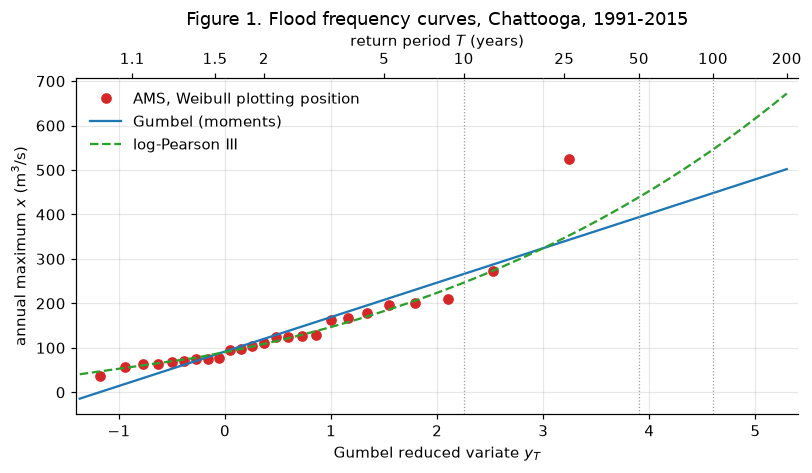

In [6]:
TT = np.linspace(1.02, 200, 600)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(y_T(T_emp), x_sorted, "o", color="tab:red", label="AMS, Weibull plotting position")
ax.plot(y_T(TT), x_bar + K_gumbel(TT) * s, "-", color="tab:blue", label="Gumbel (moments)")
ax.plot(y_T(TT), 10 ** (y_bar + stats.pearson3.ppf(1 - 1/TT, Cs) * s_y), "--", color="tab:green", label="log-Pearson III")
for Ti in T:
    ax.axvline(y_T(Ti), color="0.6", lw=0.8, ls=":")
T_ticks = np.array([1.1, 1.5, 2, 5, 10, 25, 50, 100, 200])
top = ax.secondary_xaxis("top", functions=(lambda v: v, lambda v: v))
top.set_xticks(y_T(T_ticks)); top.set_xticklabels([f"{t:g}" for t in T_ticks]); top.set_xlabel("return period $T$ (years)")
ax.set(xlabel="Gumbel reduced variate $y_T$", ylabel="annual maximum $x$ (m$^3$/s)", xlim=(-1.4, 5.4),
       title="Figure 1. Flood frequency curves, Chattooga, 1991-2015")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

**Reading Figure 1.** The Gumbel is the straight line, the LP3 the curve that bends upward because the logs have positive skew ($C_s = 0.51$). Both follow the points well up to about $T = 10$ years, and both give a 10-year flood near 250 to 270 m$^3$/s (Gumbel 266, LP3 247). They part company beyond the data: the 50-year flood is 394 (Gumbel) or 439 (LP3) m$^3$/s and the 100-year flood 448 or 546 m$^3$/s. Neither curve reaches the 2004 flood (524 m$^3$/s) at its plotting position of 26 years; on the LP3 it is about an 87-year flood and on the Gumbel about a 265-year flood. That single year shows how much the answer depends on the choice of distribution once we extrapolate. (At the low end the straight Gumbel line even dips below zero, a reminder that a fit is judged where it is used, at the rare end.)

## 6) How sure is a 100-year flood from 25 years?

We have one 25-year record; another 25 years would have given a different record and a different $x_{100}$. The **bootstrap** imitates this: draw 25 values at random from our 25, with repeats allowed, refit, and repeat 2000 times. The spread of the 2000 answers shows how much $x_{100}$ could change with a different sample. We report the middle 90 % (from the 5th to the 95th percentile).

Gumbel x_100: 448 m3/s; bootstrap 90 % range 261 to 618 m3/s
LP3    x_100: 546 m3/s; bootstrap 90 % range 269 to 908 m3/s


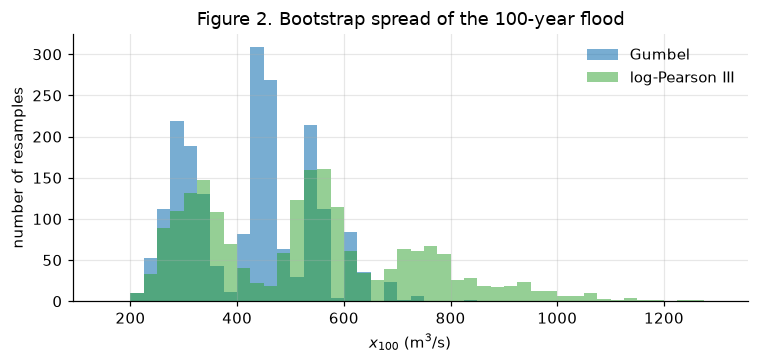

In [7]:
def x100_both(sample):
    xb, sd = sample.mean(), sample.std(ddof=1)
    ys = np.log10(sample)
    return xb + K_gumbel(100) * sd, 10 ** (ys.mean() + stats.pearson3.ppf(0.99, stats.skew(ys, bias=False)) * ys.std(ddof=1))

rng = np.random.default_rng(25)
boot = np.array([x100_both(rng.choice(x, n, replace=True)) for _ in range(2000)])
lo, mid, hi = np.percentile(boot, [5, 50, 95], axis=0)
for j, name in enumerate(["Gumbel", "LP3"]):
    print(f"{name:6s} x_100: {[xT_gum, xT_lp3][j][-1]:.0f} m3/s; bootstrap 90 % range {lo[j]:.0f} to {hi[j]:.0f} m3/s")

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(150, 1300, 47)
ax.hist(boot[:, 0], bins, alpha=0.6, color="tab:blue", label="Gumbel")
ax.hist(boot[:, 1], bins, alpha=0.5, color="tab:green", label="log-Pearson III")
ax.set(xlabel="$x_{100}$ (m$^3$/s)", ylabel="number of resamples", title="Figure 2. Bootstrap spread of the 100-year flood")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

The humps in Figure 2 come from how often the 2004 flood is drawn: resamples without it give a Gumbel $x_{100}$ near 300 m$^3$/s, those with it once near 450, twice near 540. One flood year steers the whole estimate.

The Gumbel 100-year flood of 448 m$^3$/s could, with another 25 years of the same climate, plausibly be anywhere from about 260 to 620 m$^3$/s; the LP3 range is wider still, roughly 270 to 910 m$^3$/s, because its skew is itself uncertain. Both ranges include the other method's answer. A rule of thumb follows: a record of $n$ years gives fair estimates up to about $T = n$ and rough ones up to $T = 2n$; beyond that, add longer records, nearby gauges (regional frequency analysis), historical flood marks, or a rainfall-runoff model (Lecture 7) driven by long rainfall series (Lecture 21).

## 7) Design flood

The **design flood** is the flood a structure must pass without failure. Choosing it means choosing an acceptable risk (Lecture 24): a failure that would kill people downstream justifies a far rarer flood than one that floods a field. Indian practice, in broad terms (check the current code before using these numbers):

| Structure | Typical design flood |
|:--|:--|
| Large dam (IS 11223: gross storage above about 60 million m$^3$ or head above about 30 m) | probable maximum flood (PMF) |
| Intermediate dam (smaller storage or head) | standard project flood (SPF), a severe but not extreme flood |
| Small dam | about the 100-year flood |
| Barrages, weirs, road and rail bridges | about the 50- to 100-year flood, plus checks for a larger flood |
| Flood embankments | often the 25-year flood for farmland and the 100-year flood for towns |
| Urban storm drains | a short return period, a few years (roughly 2 to 10) |

The PMF is not a return-period flood: it comes from the probable maximum precipitation (PMP) for the catchment, turned into a flood with a unit hydrograph. Newer Central Water Commission guidance for dam safety also classifies dams by **hazard potential** (what lies downstream), not by size alone. A structure is also given a **freeboard**: an extra height above the design flood level that allows for waves, wind set-up, settlement and the uncertainty of Section 6.

## 8) Climate change and floods

Every formula so far assumes a **stationary** climate: the 100-year flood of 1991-2015 stays the 100-year flood. Warming breaks this. Warmer air holds more water vapour, about 7 % more per kelvin (the Clausius-Clapeyron rate of Lecture 4), and the heaviest rainfalls tend to grow at about that rate. Lecture 4's energy-balance model gave about 2.4 K of warming by 2100 under SSP2-4.5 and a 17 % rise in moisture capacity.

A **simple nonstationary sketch.** Suppose the region warms by $\Delta T_{air} = 2$ K beyond the record period, and suppose (crudely) that every annual flood grows with heavy rain by the factor

$$
c = 1.07^{\Delta T_{air}} = 1.07^{2} = 1.145 .
$$

Then $\bar x$ and $s$ both grow by 14.5 %, $K_T$ is unchanged, and so $x_T = c\,(\bar x + K_T s)$ grows by 14.5 % too. Real floods do not scale so simply: wetter or drier soils, less snow, land-use change and reservoirs all matter, and some rivers will see smaller floods. The sketch only shows the arithmetic of a shifted distribution.

c = 1.1449;  Gumbel x_100: 448 -> 513 m3/s
today's 100-year flood (448 m3/s) becomes a 48-year flood
mean Rx1day: 84.7 -> 97.0 mm


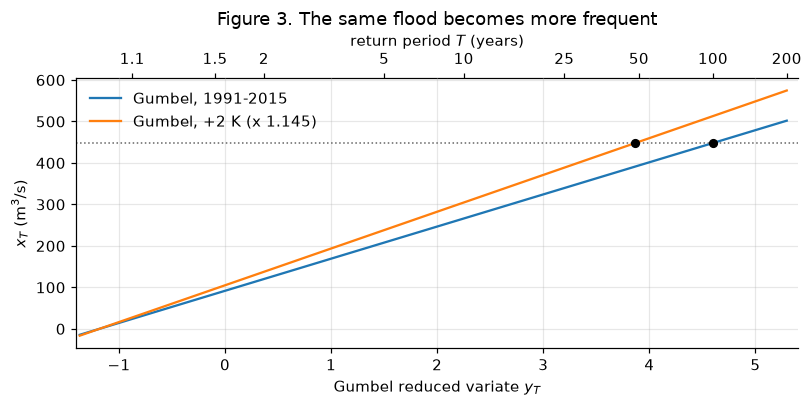

In [8]:
dT = 2.0
c = 1.07 ** dT
u_f, alpha_f = c * u, c * alpha                 # scaling x by c scales the Gumbel location and scale by c
x100_now, x100_fut = xT_gum[-1], c * xT_gum[-1]
T_old_in_future = 1 / stats.gumbel_r.sf(x100_now, loc=u_f, scale=alpha_f)
print(f"c = {c:.4f};  Gumbel x_100: {x100_now:.0f} -> {x100_fut:.0f} m3/s")
print(f"today's 100-year flood ({x100_now:.0f} m3/s) becomes a {T_old_in_future:.0f}-year flood")
rx1 = df["prcp_mm"].groupby(df.index.year).max().mean()           # mean Rx1day, Lecture 24
print(f"mean Rx1day: {rx1:.1f} -> {rx1 * c:.1f} mm")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(y_T(TT), stats.gumbel_r.isf(1/TT, loc=u, scale=alpha), color="tab:blue", label="Gumbel, 1991-2015")
ax.plot(y_T(TT), stats.gumbel_r.isf(1/TT, loc=u_f, scale=alpha_f), color="tab:orange", label=f"Gumbel, +{dT:.0f} K (x {c:.3f})")
ax.axhline(x100_now, color="0.4", ls=":", lw=1)
ax.plot([y_T(100), y_T(T_old_in_future)], [x100_now, x100_now], "ko", ms=5)
top = ax.secondary_xaxis("top", functions=(lambda v: v, lambda v: v))
top.set_xticks(y_T(T_ticks)); top.set_xticklabels([f"{t:g}" for t in T_ticks]); top.set_xlabel("return period $T$ (years)")
ax.set(xlabel="Gumbel reduced variate $y_T$", ylabel="$x_T$ (m$^3$/s)", xlim=(-1.4, 5.4),
       title="Figure 3. The same flood becomes more frequent")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

With 2 K of extra warming the Gumbel 100-year flood grows from 448 to 513 m$^3$/s, and today's 100-year flood becomes roughly a **48-year** flood: it comes about twice as often. A 14.5 % change is smaller than the bootstrap range of Section 6, which is why such changes are hard to see in one short record (Lecture 24 found no significant trend in Rx1day) yet still matter for a structure built to last 50 to 100 years.

**Glacial lake outburst floods.** In the Himalaya, warming also changes the source of floods. Retreating glaciers leave lakes dammed by loose moraine; many have grown in number and size. A moraine dam can fail from overtopping by an ice or rock avalanche, from melting buried ice, or from an earthquake, and release in minutes a flood far larger than any rainfall flood of the valley (South Lhonak, Sikkim, 2023). GLOFs are not handled by frequency analysis of a gauge record; they are assessed lake by lake (lake volume, dam stability, what lies downstream), with satellite monitoring of lakes by agencies such as the CWC and NDMA.

**Flood-risk and floodplain management.** Since risk = hazard $\times$ exposure $\times$ vulnerability (Lecture 24), there are three ways to cut it:

- *Reduce the hazard:* reservoirs that hold back the flood peak, embankments, channel improvements. Embankments protect up to their design flood and can make a rarer flood worse when they breach (Kosi, 2008).
- *Reduce exposure:* **floodplain zoning**, which keeps homes and hospitals out of the area flooded by, say, the 100-year flood and allows parks or farming there. India's model floodplain zoning bill (1975) proposed this, but few states have enacted it.
- *Reduce vulnerability:* **early warning**, flood-proof buildings, insurance and relief planning. Lecture 10 showed that a flood wave travels downstream at its celerity, about 1.6 m/s in that example, so a town 100 km below an upstream gauge gets roughly 17 hours of lead time. Forecasts of rain extend that lead time further; the CWC issues flood forecasts at many such stations.

## Summary

- The frequency factor method writes every $T$-year flood as $x_T = \bar x + K_T s$; the distribution decides $K_T$.
- Gumbel by moments: $\alpha = (\sqrt 6/\pi)s$, $u = \bar x - 0.5772\alpha$, $K_T = -(\sqrt 6/\pi)\{0.5772 + \ln[\ln(T/(T-1))]\}$. Hand example: $x_{100} = 885$ m$^3$/s.
- Log-Pearson III works on $y = \log_{10}x$ and takes $K_T$ from the skew $C_s$ (table, Kite formula or `pearson3.ppf`).
- Chattooga: the 100-year flood is 448 m$^3$/s (Gumbel) or 546 m$^3$/s (LP3), and the bootstrap 90 % range from only 25 years is about 260 to 620 m$^3$/s (Gumbel) and 270 to 910 m$^3$/s (LP3).
- The design flood is chosen by the consequence of failure: the PMF for large dams, around 50 to 100 years for bridges and small dams, a few years for drains, plus freeboard.
- Warming of 2 K with Clausius-Clapeyron scaling turns today's 100-year flood into roughly a 50-year flood; GLOFs and floodplain management need site-by-site and non-structural responses.

## Check your understanding

1. Why does the Gumbel $K_T$ not depend on the data, while the LP3 $K_T$ does?
2. The Gumbel and LP3 fits agree at $T = 10$ but differ by about 100 m$^3$/s at $T = 100$. Why do they agree where they do and differ where they do?
3. If every flood grows by 14.5 %, why does the 100-year flood grow by exactly 14.5 % while its return period changes by about half?

## Try it yourself

- Remove the 2004 flood from the Chattooga AMS and refit both distributions. How much do $x_{100}$ and $C_s$ change?
- In the workbook sheet `Gumbel`, change the hand-example flood of 2015 from 710 to 900 m$^3$/s. How do $s$ and $x_{100}$ change?
- Repeat Section 8 with $\Delta T_{air} = 1$ K and 4 K. What return period does today's 100-year flood have in each case?

```{note} Sources
Written for **CE524 Applied Hydroclimatology**. The frequency factor method, the Gumbel (EV1) fit by moments, the log-Pearson III procedure and the Kite approximation of $K_T$ follow Chow, V. T., Maidment, D. R., & Mays, L. W. (1988). *Applied Hydrology*. McGraw-Hill, **Chapter 12** (Sections 12.2 and 12.3). Log-Pearson III practice: Interagency Advisory Committee on Water Data (1982), *Guidelines for Determining Flood Flow Frequency*, Bulletin 17B, USGS (updated as Bulletin 17C, England et al., 2019). Kite, G. W. (1977). *Frequency and Risk Analyses in Hydrology*. Water Resources Publications. Spillway design floods: Bureau of Indian Standards, IS 11223 (1985), *Guidelines for fixing spillway capacity*; check current CWC dam-safety guidance before design use. Clausius-Clapeyron scaling of heavy rain: Trenberth, K. E., Dai, A., Rasmussen, R. M., & Parsons, D. B. (2003). *Bull. Amer. Meteor. Soc., 84*, 1205&ndash;1217. The explanations, the hand example, the workbook and the figures were made for this course and do not reproduce the book's text, tables or examples.

**Data.** `data/chattooga_daily.csv` (USGS 02177000, Daymet v4), as in Lectures 7, 10 and 24. The design-flood table summarises common practice in general terms and the climate scaling is illustrative, not a projection for any river. Related lectures: 4 (Clausius-Clapeyron), 7 (rainfall-runoff), 10 (routing and lead time), 14 (scenarios and uncertainty), 17 (distributions and moments), 21 (weather generators), 24 (return periods).

Text under CC BY-SA 4.0, code additionally under the MIT License; full attribution in [CREDITS.md](https://github.com/drvivekhydro/hydroclimatology/blob/main/CREDITS.md).
```